# Memory & State 관리

Agent가 대화를 이어가려면 **State를 저장하고 복원**하는 기능이 필요하다. LangGraph는 이를 위해 Checkpointer(Short-term Memory)와 Store(Long-term Memory)를 제공한다.

In [19]:

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.messages import HumanMessage, RemoveMessage, SystemMessage, trim_messages
from langchain_core.runnables import RunnableConfig
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.store.base import BaseStore
from langgraph.store.memory import InMemoryStore

load_dotenv()

MODEL_NAME = "gemini-3.6-flash"

llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

## 기본 챗봇 그래프

Memory 기능을 실습하기 위한 간단한 챗봇 그래프를 먼저 구성한다.

In [20]:
def simple_chatbot(state: MessagesState):
    return {"messages": [llm.invoke(state["messages"])]}


simple_builder = StateGraph(MessagesState)
simple_builder.add_node("chatbot", simple_chatbot)

simple_builder.add_edge(START, "chatbot")
simple_builder.add_edge("chatbot", END)

print("기본 챗봇 그래프 구성 완료")

기본 챗봇 그래프 구성 완료


### Checkpointer와 Saver

Checkpointer는 그래프의 State 스냅샷을 저장하고 복원하는 기능이다. 그래프 실행 시작 시와 각 노드 실행 후에 State를 저장하며, 같은 `thread_id`로 다시 호출하면 저장된 상태를 바탕으로 실행을 이어간다.

Saver는 Checkpointer가 생성한 스냅샷을 실제로 저장하는 저장소 구현체다. 저장 위치에 따라 메모리, SQLite, PostgreSQL 등의 Saver를 선택할 수 있으며, 어떤 Saver를 사용하더라도 `thread_id`로 상태 이력을 구분한다. 이번 실습에서는 메모리에 스냅샷을 저장하는 `MemorySaver`를 사용한다.

In [4]:
memory = MemorySaver()

# checkpointer와 함께 컴파일
graph_with_memory = simple_builder.compile(checkpointer=memory)

print("Checkpointer 연결 완료")

Checkpointer 연결 완료


In [5]:
# thread_id로 대화 세션을 구분한다
config = {"configurable": {"thread_id": "session-1"}}

# 첫 번째 대화
result = graph_with_memory.invoke(
    {"messages": [("human", "내 이름은 철수야. 반가워!")]},
    config=config,
)
print(result["messages"][-1].text)
print()

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


안녕하세요, 철수님! 만나서 반갑습니다. 😊 

저는 무엇이든 도와드릴 수 있는 AI 도우미예요. 오늘 어떤 이야기나 궁금한 점이 있으신가요? 편하게 말씀해 주세요!



In [6]:
# 두 번째 대화 - 같은 thread_id이므로 이전 대화를 기억한다
result = graph_with_memory.invoke(
    {"messages": [("human", "내 이름이 뭐라고 했지?")]},
    config=config,
)
print(result["messages"][-1].text)
print()

'철수'라고 하셨어요! 제가 잘 기억하고 있답니다. 😉



In [7]:
# 다른 thread_id는 별도의 세션이다
config2 = {"configurable": {"thread_id": "session-2"}}

result = graph_with_memory.invoke(
    {"messages": [("human", "내 이름이 뭐야?")]},
    config=config2,
)
print(result["messages"][-1].text)
print("-> 다른 세션이므로 이름을 모른다")

저는 당신의 이름을 알지 못합니다. 알려주시면 기억할게요! 

이름이 어떻게 되시나요?
-> 다른 세션이므로 이름을 모른다


### 저장된 State 확인

`get_state(config)`를 호출하면 해당 `thread_id`의 최신 State를 확인할 수 있다. 실제 State 데이터는 `values`에 저장되어 있다.

```python
state = graph_with_memory.get_state(config)
state.values  # {"messages": [...]}
```

In [8]:
state = graph_with_memory.get_state(config)
print(f"저장된 메시지 수: {len(state.values['messages'])}")
for msg in state.values["messages"]:
    print(f"  [{msg.type}] {msg.text}")

저장된 메시지 수: 4
  [human] 내 이름은 철수야. 반가워!
  [ai] 안녕하세요, 철수님! 만나서 반갑습니다. 😊 

저는 무엇이든 도와드릴 수 있는 AI 도우미예요. 오늘 어떤 이야기나 궁금한 점이 있으신가요? 편하게 말씀해 주세요!
  [human] 내 이름이 뭐라고 했지?
  [ai] '철수'라고 하셨어요! 제가 잘 기억하고 있답니다. 😉


`get_state_history(config)`를 호출하면 해당 `thread_id`에 저장된 과거 State 스냅샷을 확인할 수 있다. 반환값은 iterator이며, 최신 스냅샷부터 조회된다.

In [9]:
history = list(graph_with_memory.get_state_history(config))

for index, snapshot in enumerate(history):
    print(f"\n[스냅샷 {index}]")
    for msg in snapshot.values.get("messages", []):
        print(f"  [{msg.type}] {msg.text}")


[스냅샷 0]
  [human] 내 이름은 철수야. 반가워!
  [ai] 안녕하세요, 철수님! 만나서 반갑습니다. 😊 

저는 무엇이든 도와드릴 수 있는 AI 도우미예요. 오늘 어떤 이야기나 궁금한 점이 있으신가요? 편하게 말씀해 주세요!
  [human] 내 이름이 뭐라고 했지?
  [ai] '철수'라고 하셨어요! 제가 잘 기억하고 있답니다. 😉

[스냅샷 1]
  [human] 내 이름은 철수야. 반가워!
  [ai] 안녕하세요, 철수님! 만나서 반갑습니다. 😊 

저는 무엇이든 도와드릴 수 있는 AI 도우미예요. 오늘 어떤 이야기나 궁금한 점이 있으신가요? 편하게 말씀해 주세요!
  [human] 내 이름이 뭐라고 했지?

[스냅샷 2]
  [human] 내 이름은 철수야. 반가워!
  [ai] 안녕하세요, 철수님! 만나서 반갑습니다. 😊 

저는 무엇이든 도와드릴 수 있는 AI 도우미예요. 오늘 어떤 이야기나 궁금한 점이 있으신가요? 편하게 말씀해 주세요!

[스냅샷 3]
  [human] 내 이름은 철수야. 반가워!
  [ai] 안녕하세요, 철수님! 만나서 반갑습니다. 😊 

저는 무엇이든 도와드릴 수 있는 AI 도우미예요. 오늘 어떤 이야기나 궁금한 점이 있으신가요? 편하게 말씀해 주세요!

[스냅샷 4]
  [human] 내 이름은 철수야. 반가워!

[스냅샷 5]


### Long-term Memory

Checkpointer는 `thread_id` 단위로 대화 State를 저장한다. 반면 Store는 스레드를 넘어 사용자 정보를 저장하는 **Long-term Memory**다.

| 구분 | Checkpointer | Store |
|---|---|---|
| 구분 기준 | `thread_id` | namespace, key |
| 용도 | 같은 대화 이어가기 | 다른 대화에서도 사용자 정보 사용하기 |


- **namespace**: 사용자별 데이터를 묶는 저장 경로
- **key**: namespace 안에서 프로필을 식별하는 값 
- **value**: 실제로 저장할 사용자 이름과 관심 분야

여기서 Long-term은 데이터가 반드시 영구 보존된다는 뜻이 아니라, 하나의 대화 스레드를 넘어 공유된다는 의미다.

### Store는 언제 사용하는가

정보가 현재 대화에만 필요한지, 다른 대화에서도 다시 필요할지를 기준으로 저장 위치를 선택한다.

| 저장할 정보 | 적합한 위치 | 예시 |
|---|---|---|
| 현재 대화의 흐름과 중간 결과 | State와 Checkpointer | 메시지 기록, 현재 작업 단계, 도구 실행 결과 |
| 여러 대화에서 재사용할 정보 | Store | 사용자 프로필, 선호 언어, 관심 분야, 장기 설정 |
| 모든 사용자가 함께 사용하는 정보 | Store | 공통 정책, 애플리케이션 설정 |

Store에는 이후 대화에서 다시 활용할 가치가 있는 정보만 저장한다. 매번 달라지는 임시 값이나 전체 대화 기록을 무분별하게 저장하면 오래된 정보가 사용되거나 불필요한 데이터가 쌓일 수 있다.

이 예제에서는 그래프 실행 전에 `store.put()`으로 프로필을 저장하고, `memory_chatbot` 노드가 실행될 때 `store.get()`으로 조회한다. 실제 애플리케이션에서는 회원가입이나 설정 변경 시 프로필을 저장하거나, 사용자가 기억해 달라고 요청한 정보를 별도의 노드 또는 도구에서 저장할 수 있다.

### Store 기본 메서드

- `put(namespace, key, value)`: namespace와 key를 기준으로 데이터를 저장한다
- `get(namespace, key)`: namespace와 key가 일치하는 데이터 하나를 조회한다
- `search(namespace)`: namespace에 저장된 데이터 목록을 조회한다

```python
store.put(namespace, key, value)
item = store.get(namespace, key)
items = store.search(namespace)
```

In [10]:
store = InMemoryStore()
user_id = "user-001"
user_namespace = ("users", user_id)

store.put(
    namespace=user_namespace,
    key="profile",
    value={"name": "철수", "interest": "Python"},
)

profile = store.get(user_namespace, "profile")
print(f"key={profile.key}, value={profile.value}")

key=profile, value={'name': '철수', 'interest': 'Python'}


### Store를 사용하는 노드

기본 챗봇 노드는 State만 사용했지만, 다음 노드는 실행 설정과 Store도 함께 사용한다. LangGraph는 노드를 실행할 때 함수의 매개변수에 맞춰 이 값들을 전달한다.

- `state: MessagesState`: 현재 스레드의 메시지가 들어 있는 State
- `config: RunnableConfig`: 호출 시 전달한 실행 설정으로, 이 예제에서는 `configurable` 안의 `user_id`를 읽는다
- `store: BaseStore`: `compile(store=store)`로 연결한 Store이며 LangGraph가 노드에 전달한다

In [11]:
def memory_chatbot(
    state: MessagesState,
    config: RunnableConfig,
    store: BaseStore,
):
    user_id = config["configurable"]["user_id"]
    namespace = ("users", user_id)
    profile = store.get(namespace, "profile")

    if profile:
        system = (
            "다음 사용자 프로필을 참고하여 답변하세요.\n"
            f"이름: {profile.value['name']}\n"
            f"관심 분야: {profile.value['interest']}"
        )
    else:
        system = "저장된 사용자 프로필이 없습니다."
    response = llm.invoke([SystemMessage(content=system), *state["messages"]])

    return {"messages": [response]}


memory_builder = StateGraph(MessagesState)
memory_builder.add_node("chatbot", memory_chatbot)
memory_builder.add_edge(START, "chatbot")
memory_builder.add_edge("chatbot", END)

memory_graph = memory_builder.compile(
    checkpointer=MemorySaver(),
    store=store,
)

### 새로운 대화에서 Store 사용

`thread_id`가 달라지면 Checkpointer의 대화 State는 공유되지 않는다. 그러나 같은 `user_id`를 사용하면 Store에 저장된 사용자 정보는 새로운 대화에서도 조회할 수 있다.

In [12]:
config_1 = {
    "configurable": {
        "thread_id": "conversation-1",
        "user_id": "user-001",
    }
}
config_2 = {
    "configurable": {
        "thread_id": "conversation-2",
        "user_id": "user-001",
    }
}

result_1 = memory_graph.invoke(
    {"messages": [("human", "내 이름과 관심 분야를 알려줘.")]},
    config=config_1,
)
result_2 = memory_graph.invoke(
    {"messages": [("human", "나에 대해 알고 있는 정보를 알려줘.")]},
    config=config_2,
)

print(f"[thread-1] {result_1['messages'][-1].text}")
print(f"[thread-2] {result_2['messages'][-1].text}")

[thread-1] 당신의 이름은 **철수**이고, 관심 분야는 **Python**입니다.
[thread-2] 안녕하세요, 철수님! 제가 현재 알고 있는 철수님에 대한 정보는 다음과 같습니다.

* **이름:** 철수
* **관심 분야:** Python (파이썬)

혹시 Python 공부나 프로젝트와 관련해서 도움이 필요하시다면 언제든 편하게 말씀해 주세요!


### namespace를 이용한 사용자 데이터 분리

Store는 namespace와 key의 조합으로 데이터를 구분한다. 따라서 같은 `profile` key를 사용하더라도 사용자 식별자를 namespace에 포함하면 사용자별 프로필이 서로 섞이지 않는다.

```text
("users", "user-001") / profile → 철수의 프로필
("users", "user-002") / profile → 영희의 프로필
```

아래 실습에서는 두 사용자의 프로필을 같은 `profile` key로 저장한다. 이후 서로 다른 `user_id`로 챗봇을 호출하여 각 사용자의 namespace에 저장된 프로필만 조회하는지 확인한다.

이 방식은 데이터를 논리적으로 분리하는 저장 규칙이다. namespace 자체가 인증이나 접근 권한을 검사하지는 않으므로, 실제 서비스에서는 클라이언트가 보낸 `user_id`를 그대로 신뢰하지 않고 인증된 사용자 정보로 namespace를 만들어야 한다.

In [13]:
user_profiles = {
    "user-001": {"name": "철수", "interest": "Python"},
    "user-002": {"name": "영희", "interest": "JavaScript"},
}

# 같은 key를 사용하지만 사용자별 namespace에 각각 저장한다.
for user_id, profile in user_profiles.items():
    store.put(
        namespace=("users", user_id),
        key="profile",
        value=profile,
    )

user_configs = {
    "user-001": {
        "configurable": {
            "thread_id": "user-001-thread",
            "user_id": "user-001",
        }
    },
    "user-002": {
        "configurable": {
            "thread_id": "user-002-thread",
            "user_id": "user-002",
        }
    },
}

# 각 사용자는 자신의 namespace에 저장된 프로필만 전달받는다.
for user_id, config in user_configs.items():
    result = memory_graph.invoke(
        {"messages": [("human", "내 이름과 관심 분야를 알려줘.")]},
        config=config,
    )
    print(f"[{user_id}] {result['messages'][-1].text}")

[user-001] 안녕하세요, 철수님! 

제공해주신 프로필에 따른 정보는 다음과 같습니다.

* **이름:** 철수
* **관심 분야:** Python
[user-002] 영희님의 프로필 정보는 다음과 같습니다.

* **이름:** 영희
* **관심 분야:** JavaScript


### 대화 요약 관리

대화가 길어지면 메시지가 계속 누적되어 토큰 비용이 증가한다. 전체 토큰 수가 임계값을 넘으면 **요약 노드**가 실행되어, `trim_messages`로 최근 메시지만 남기고 나머지를 요약으로 대체하는 패턴을 구현한다.

```
START → chatbot → 토큰 초과 → summarize → END
                → 토큰 이내 →             END
```

핵심 도구:
- `trim_messages`: 토큰 기준으로 최근 메시지만 유지한다
- `RemoveMessage`: State에서 특정 메시지를 **ID 기반으로 삭제**한다. `add_messages` reducer가 `RemoveMessage`를 만나면 해당 ID의 메시지를 제거한다

요약 후 State 구조:
```
messages: [최근 human 메시지, 최근 ai 응답]   ← trim 후 남은 것만
summary: "이전 대화 요약 텍스트"              ← 삭제된 메시지의 요약
```

`RemoveMessage`로 삭제된 메시지는 현재 State에서 완전히 사라진다. Checkpointer 히스토리에는 과거 스냅샷이 남아있지만, 그래프가 사용하는 현재 State에는 없다.

### 요약 State 정의

`MessagesState`를 상속하고, 오래된 대화의 요약을 저장할 `summary` 필드를 추가한다.

In [14]:
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

MAX_TOKENS = 200  # 네 번째 대화 전에 요약이 동작하도록 낮게 설정


class SummaryState(MessagesState):
    """최근 메시지와 오래된 대화의 요약을 관리하는 State."""

    summary: str

### 답변 생성과 요약 조건

기존 요약이 있으면 합성된 `HumanMessage`로 최근 메시지 앞에 추가하여 답변을 생성한다. 이 메시지는 모델 호출에만 사용하고 State에는 저장하지 않는다. 답변 생성 후 전체 메시지가 `MAX_TOKENS`를 초과하면 요약 노드로 이동한다.

In [15]:
def chatbot_with_summary(state: SummaryState):
    """기존 요약과 최근 메시지를 사용하여 답변한다."""
    messages = [SystemMessage(content="모든 답변을 2문장 이내로 짧게 해줘.")]

    # 요약을 합성된 HumanMessage로 전달하되 State에는 저장하지 않는다.
    if state.get("summary"):
        messages.append(
            HumanMessage(
                content=f"이전 대화 요약:\n{state['summary']}",
                additional_kwargs={"lc_source": "summarization"},
            )
        )

    messages.extend(state["messages"])
    response = llm.invoke(messages)

    return {"messages": [response]}


def route_after_chatbot(state: SummaryState):
    """토큰 수에 따라 요약 실행 여부를 결정한다."""
    # 현재 메시지의 토큰 수를 계산한다.
    token_count = llm.get_num_tokens_from_messages(state["messages"])

    if token_count > MAX_TOKENS:
        return "summarize"
    return END

### 오래된 대화 요약

`trim_messages`로 최근 메시지와 요약할 메시지를 나눈다. 오래된 메시지는 `summary`에 반영하고, `RemoveMessage`로 현재 `messages`에서 제거한다.

In [16]:
def print_history(title, messages):
    """메시지 목록을 역할과 함께 출력한다."""
    print(f"\n[{title}]")
    if not messages:
        print("(없음)")
        return

    for index, message in enumerate(messages, start=1):
        print(f"{index}. [{message.type}] {message.content}")


def summarize_conversation(state: SummaryState):
    """오래된 메시지를 요약하고 최근 메시지만 유지한다."""
    # 현재 메시지와 이전에 생성한 요약을 State에서 가져온다.
    messages = state["messages"]
    existing_summary = state.get("summary", "")

    # 최근 100토큰 이내의 메시지는 원문 그대로 유지한다.
    kept_messages = trim_messages(
        messages,
        max_tokens=100,
        strategy="last",
        token_counter=llm,
        start_on="human",
    )

    # 유지할 메시지를 제외한 나머지를 요약 대상으로 분리한다.
    kept_ids = {message.id for message in kept_messages}
    messages_to_summarize = [
        message for message in messages if message.id not in kept_ids
    ]

    summary_instruction = (
        "대화 맥락에 필요한 핵심 정보만 요약해줘.\n"
        "- 2문장, 150자 이내\n"
        "- 제목, 불릿, 서론 없이 요약문만 출력\n"
        "- 중복된 내용은 제거\n"
        "- 사용자 이름과 선호처럼 이후 대화에 필요한 정보는 반드시 유지"
    )

    # 기존 요약이 있으면 새 대화 내용을 더해 요약을 갱신한다.
    if existing_summary:
        prompt = (
            f"{summary_instruction}\n\n"
            f"기존 요약:\n{existing_summary}\n\n"
            "새 대화:\n"
        )
    else:
        prompt = f"{summary_instruction}\n\n대화:\n"

    # 요약 대상 메시지만 프롬프트에 추가한다.
    for message in messages_to_summarize:
        if message.type in ("human", "ai") and message.content:
            prompt += f"{message.type}: {message.content}\n"

    # 생성된 요약은 State의 summary 필드에 저장된다.
    summary_response = llm.invoke(prompt)

    print_history("압축 전 History", messages)
    print_history("summary로 압축할 History", messages_to_summarize)
    print(f"\n[생성된 summary]\n{summary_response.text}")
    print_history("압축 후 messages에 유지할 History", kept_messages)

    # 요약한 원본 메시지는 RemoveMessage로 현재 messages에서 제거한다.
    # 다음 LLM 호출에서는 summary가 합성된 HumanMessage로 전달된다.
    return {
        "summary": summary_response.text,
        "messages": [
            RemoveMessage(id=message.id) for message in messages_to_summarize
        ],
    }

### 요약 그래프 구성

답변 생성 후 조건에 따라 종료하거나 요약 노드를 실행하도록 연결한다.

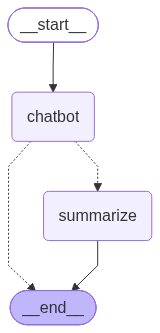

In [17]:
summary_builder = StateGraph(SummaryState)

summary_builder.add_node("chatbot", chatbot_with_summary)
summary_builder.add_node("summarize", summarize_conversation)

summary_builder.add_edge(START, "chatbot")
summary_builder.add_conditional_edges(
    "chatbot",
    route_after_chatbot,
    {"summarize": "summarize", END: END},
)
summary_builder.add_edge("summarize", END)

summary_memory = MemorySaver()
summary_graph = summary_builder.compile(checkpointer=summary_memory)

display(Image(summary_graph.get_graph().draw_mermaid_png()))

### 요약 과정 확인

같은 `thread_id`로 대화를 반복하면서 `messages`가 누적되고 `summary`로 압축되는 과정을 확인한다.

In [18]:
def run_turn(question, config):
    """한 차례 대화를 실행하고 현재 State를 출력한다."""
    result = summary_graph.invoke(
        {"messages": [("human", question)]},
        config=config,
    )
    print_history("현재 State의 messages", result["messages"])
    print(f"\n현재 summary: {result.get('summary', '(요약 없음)')}")

    return result


config = {"configurable": {"thread_id": "summary-test"}}

questions = [
    "내 이름은 철수야. 기억해줘.",
    "파이썬이 뭐야?",
    "자바스크립트와 비교하면?",
    "웹 개발에는 어떤 게 좋아?",
    "데이터 분석에는?",
    "내 이름이 뭐라고 했지?",
]

for turn, question in enumerate(questions, start=1):
    print("\n" + "=" * 60)
    print(f"Turn {turn}: {question}")
    run_turn(question, config)


Turn 1: 내 이름은 철수야. 기억해줘.

[현재 State의 messages]
1. [human] 내 이름은 철수야. 기억해줘.
2. [ai] [{'type': 'text', 'text': '반갑습니다, 철수님! \n\n철수님의 이름을 잘 기억해 두겠습니다.', 'extras': {'signature': 'EokICoYIARFNMg9kXE/xswFQRbV+H+YGptOwm28D5cO9SOjZ/Gqc751GPG68H6acI1fr/gK02b6dSuWaMS9LcG2JRyN6S/xoHOs0+d0HmybTB7TmKo8LeKC9isS1nWl198gw71kPRkZg7Y2xYS6mM1+UrMb3Hza0C6GYHY0P9n7nNGi5sW28DrO/PfoWMkGzos136Yx6UNFLgXrmJhwWHl2HyHjpwVIx6dyvgbQscB6Ma++sqNAjM+hLMNwZdWM2YXaNphVc1PvYNEC77ysyeUUbcvjhBKKfbvXK6mkswhSVNXEOViDxd9LKt6s0X5YWAbyF4opICaFOS2Gp4lGOVu7ZjE+1w6h/9mX4zoPScp7SHTNAq2L+SBeO5672Dm7HVtgxI6OPeTvOMB0GHYA2spcV+6yz2TpTTzueo81iX2mfOvm0DsKT0xtBeam6q5ePhANOJ7zL4BuJKjgw4cT0KUD0qbGzUDO8YNYloeDqi2kZcSh/rqi+XLsxhGeGkQ0doPNT60qnuZBpYCpykl2H86TN8WabJSJEiBGfL6wfa67i6iVanVPm8+U6g4rOOzfCRMgybgDDdfkKlwUvYbZLVuGS7J/gxNxNCdwmKga9YOnV5johWA9DJbIHqY5TwVkMkEvAaMacPPd5PYmjDJdzi0d2EVJGDc1MUQ8S5rI3Qe6s40CP+sxbKjkIxnRCXIBBNJ+gb2ZhMJCYfuHaE1y/Bq6t35ggc5EWV3uCAB/dTtnUQAUsrI8bqHbJWHwHMpjfX/4BOUOLQqpik8iF6YRlxxXNCu0WtmDh7tVZUwAHS268LhHE4SCzWz0J

### 원본 대화 보관

이 예제는 오래된 메시지를 요약한 뒤 현재 State에서 제거하며, 원본 대화는 별도로 보관하지 않는다. 실무에서는 원본 대화를 데이터베이스나 로그 저장소에 별도로 저장하고, LangGraph State에는 요약과 최근 메시지만 유지한다. Checkpointer는 그래프 실행 상태를 저장하기 위한 것으로, 원본 대화 저장소를 대체하지 않는다.

### 실습: 대화와 사용자 정보 기억하기

Checkpointer와 Store를 사용하는 챗봇을 완성한다.


In [22]:
memory = MemorySaver()
store = InMemoryStore()


store.put(
    namespace=("users", "rin"),
    key="profile",
    value={"name": "나린", "interest": "역전재판 게임"},
)

profile = store.get(("users", "rin"), "profile")
print(f"key={profile.key}, value={profile.value}")

key=profile, value={'name': '나린', 'interest': '역전재판 게임'}


In [23]:
def chatbot(
    state: MessagesState,
    config,
    store):

    user_data = config["configurable"]["user_data"]
    profile = store.get(("users", user_data), "profile")

    if profile:
        system = (
            "다음 사용자 프로필을 참고하여 답변하세요.\n"
            f"이름: {profile.value['name']}\n"
            f"관심 분야: {profile.value['interest']}"
        )
    else:
        system = "저장된 사용자 프로필이 없습니다."

    response = llm.invoke([SystemMessage(content=system), *state["messages"]])

    return {"messages": [response]}


builder = StateGraph(MessagesState)
builder.add_node("chatbot", chatbot)

builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile(
    checkpointer=memory,
    store=store,
)

In [27]:
config_1 = {
    "configurable": {
        "thread_id": "conversation-1",
        "user_data": "rin",
    }
}
config_2 = {
    "configurable": {
        "thread_id": "conversation-2",
        "user_data": "rin",
    }
}

result_1 = graph.invoke(
    {"messages": [("human", "내 이름과 관심 분야를 알려줘. 그리고 나는 음식중에는 어향가지가 좋아")]},
    config=config_1,
)
result_2 = graph.invoke(
    {"messages": [("human", "나에 대해 알고 있는 정보를 알려줘. 나는 보라색을 좋아해")]},
    config=config_2,
)

print(f"[thread-1] {result_1['messages'][-1].text}")
print(f"[thread-2] {result_2['messages'][-1].text}")

[thread-1] 네, 다시 한번 정리해서 알려드릴게요!

* **이름:** 나린
* **관심 분야:** 역전재판 게임
* **좋아하는 음식:** 어향가지

나린 님과 관련된 정보는 잘 기억하고 있습니다. 혹시 역전재판에 대해 이야기 나누고 싶으시거나 다른 궁금한 점이 있으신가요?
[thread-2] 좋아하시는 색상을 알려주셔서 감사합니다! 말씀해 주신 내용을 반영하여 나린 님에 대해 알고 있는 정보를 다시 정리해 드릴게요.

* **이름:** 나린
* **관심 분야:** 역전재판 게임
* **좋아하는 색:** 보라색 💜

보라색이라니, '역전재판'의 마요이(아야사토 마요이) 의상도 떠오르고 아주 매력적인 색이네요! 

혹시 더 알려주고 싶으신 정보나 나누고 싶은 이야기가 있으신가요?


In [ ]:
result_3 = graph.invoke(
    {"messages": [("human", "나에 대해 알고 있는 정보를 알려줘.")]},
    config=config_1,
)
result_2 = graph.invoke(
    {"messages": [("human", "나에 대해 알고 있는 정보를 알려줘.")]},
    config=config_2,
)

print(f"[thread-1] {result_1['messages'][-1].text}")
print(f"[thread-2] {result_2['messages'][-1].text}")

[thread-1] 네, 다시 한번 정리해서 알려드릴게요!

* **이름:** 나린
* **관심 분야:** 역전재판 게임
* **좋아하는 음식:** 어향가지

나린 님과 관련된 정보는 잘 기억하고 있습니다. 혹시 역전재판에 대해 이야기 나누고 싶으시거나 다른 궁금한 점이 있으신가요?
[thread-2] 현재 제가 기억하고 있는 나린 님의 정보는 다음과 같습니다!

* **이름:** 나린
* **관심 분야:** 역전재판 게임
* **좋아하는 색:** 보라색 💜

추가하고 싶으신 정보가 있거나 이야기 나누고 싶은 주제가 있다면 언제든 편하게 말씀해 주세요!


: 